# TuniShop — Machine learning 09. Suivi des modèles dans le temps

**Auteure :** Sarra Abdeljaouad · **Phase :** machine learning · **Source :** TuniShop_DWH (vues `bi`), via `05_Data/features` · **Découpage :** apprentissage 2023-2024, test 2025

## Objectif

Un modèle se dégrade quand le comportement change (exemple : SahelLog à partir de juillet 2024). Ce notebook calcule, **période par période**, les indicateurs qui permettent de le voir, et lève une **alerte** quand un seuil est dépassé. Il est conçu pour être relancé chaque mois : chaque nouvelle période dont on connaît le résultat réel s'ajoute au suivi.

| Cas | Indicateur suivi | Seuil d'alerte |
|---|---|---|
| Prévision des ventes | erreur absolue en % du mois (total des catégories) | > 20 % |
| Demande | WAPE du mois (produit × mois) | > 60 % |
| Churn | AUC du trimestre ; écart taux prévu − taux réel | AUC < 0,75 ; écart > 5 points |
| Retard | écart taux prévu − taux réel, par transporteur et par mois | écart > 5 points |
| Dérive des variables | PSI entre l'apprentissage et la dernière période | > 0,25 |

Sortie : `06_Exports/Tables/ML_suivi.csv` et `ana.ml_suivi` (une ligne par indicateur et par période, statut OK / ALERTE).

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, validation, publication

warnings.filterwarnings("ignore")
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

for dossier in (cfg.DOSSIER_MODELES, cfg.DOSSIER_PREDICTIONS):
    dossier.mkdir(parents=True, exist_ok=True)

SEUILS = {"ventes_ape": 0.20, "demande_wape": 0.60, "churn_auc": 0.75, "ecart_taux": 0.05, "psi": 0.25}
suivi = []
def ajouter(cas, objet, periode, indicateur, valeur, seuil, alerte):
    suivi.append({"cas": cas, "objet": objet, "periode": str(periode), "indicateur": indicateur,
                  "valeur": float(valeur), "seuil": float(seuil), "statut": "ALERTE" if alerte else "OK"})

## 1. Prévision des ventes : erreur de chaque mois

In [2]:
v = pd.read_parquet(cfg.DOSSIER_PREDICTIONS / "ventes_2025_test.parquet").groupby("mois")[["reel", "prevision"]].sum()
for mois, l in v.iterrows():
    ape = abs(l["prevision"] - l["reel"]) / l["reel"]
    ajouter("ventes", "total", mois.strftime("%Y-%m"), "erreur absolue (%)", ape, SEUILS["ventes_ape"], ape > SEUILS["ventes_ape"])

## 2. Demande : WAPE de chaque mois

In [3]:
d = pd.read_parquet(cfg.DOSSIER_PREDICTIONS / "demande_2025_test.parquet")
for mois, g in d.groupby("mois"):
    w = validation.metriques_regression(g["quantite"], g["prevision_retenue"])["WAPE"]
    ajouter("demande", "produit x mois", mois.strftime("%Y-%m"), "WAPE", w, SEUILS["demande_wape"], w > SEUILS["demande_wape"])

## 3. Churn : chaque trimestre

In [4]:
c = pd.read_parquet(cfg.DOSSIER_PREDICTIONS / "churn_2025_test.parquet")
for date, g in c.groupby("date_observation"):
    auc = validation.metriques_classification(g["churn"], g["proba_churn"])["AUC"]
    ecart = g["proba_churn"].mean() - g["churn"].mean()
    ajouter("churn", "tous clients", date.date(), "AUC", auc, SEUILS["churn_auc"], auc < SEUILS["churn_auc"])
    ajouter("churn", "tous clients", date.date(), "écart taux prévu - réel", ecart, SEUILS["ecart_taux"], abs(ecart) > SEUILS["ecart_taux"])

## 4. Retard : chaque mois et chaque transporteur

In [5]:
r = pd.read_parquet(cfg.DOSSIER_PREDICTIONS / "retard_2025_test.parquet")
r["mois"] = r["date_expedition"].dt.to_period("M")
for (mois, transp), g in r.groupby(["mois", "transporteur"]):
    ecart = g["proba_retard"].mean() - g["en_retard"].mean()
    ajouter("retard", transp, mois, "écart taux prévu - réel", ecart, SEUILS["ecart_taux"], abs(ecart) > SEUILS["ecart_taux"])

## 5. Dérive des variables (PSI) : apprentissage contre dernière période

In [6]:
for cas, nom, col_date in [("churn", "ml_churn", "date_observation"), ("retard", "ml_retard", "date_expedition")]:
    t = features.lire(nom)
    app = t[t["periode"] == "apprentissage"]
    derniere = t[t[col_date] > t[col_date].max() - pd.DateOffset(months=3)]
    for _, l in validation.derive(app, derniere, features.colonnes_ml(cas)).iterrows():
        if pd.notna(l["psi"]):
            ajouter(cas, l["variable"], f"3 derniers mois au {t[col_date].max().date()}", "PSI", l["psi"], SEUILS["psi"], l["psi"] > SEUILS["psi"])

## 6. Tableau de suivi et alertes

In [7]:
suivi = pd.DataFrame(suivi)
cfg.exporter_table(suivi, "ML_suivi", index=False)
alertes = suivi[suivi["statut"] == "ALERTE"]
print(f"{len(suivi)} indicateurs suivis ; {len(alertes)} alertes")
alertes.groupby(["cas", "indicateur"]).size().to_frame("alertes")

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.ml_suivi                                    123 lignes
123 indicateurs suivis ; 19 alertes


alertes
cas    indicateur                      
churn  écart taux prévu - réel        1
retard PSI                            3
       écart taux prévu - réel       14
ventes erreur absolue (%)             1

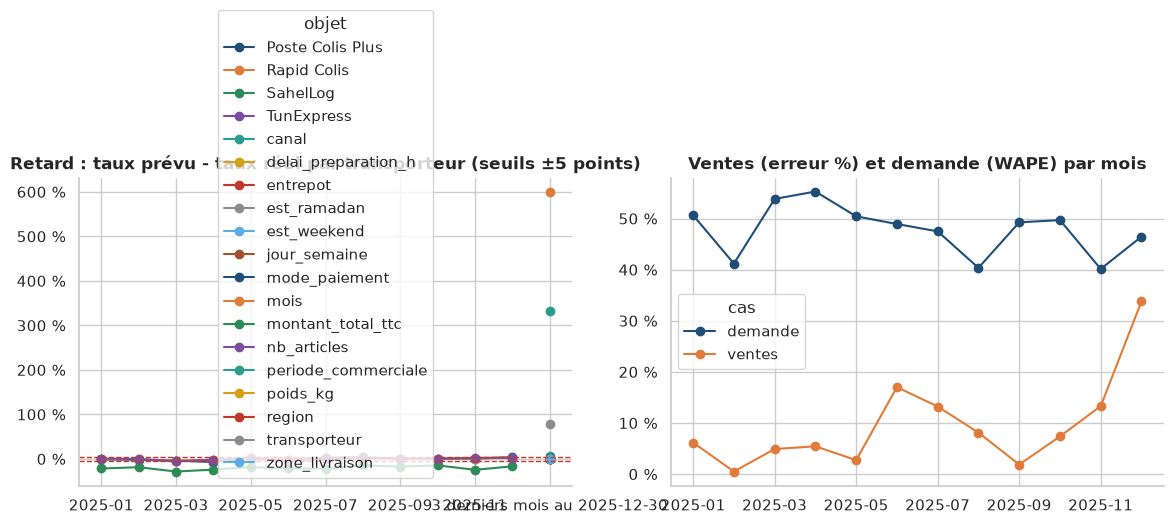

,cas,objet,periode,indicateur,valeur,seuil,statut
25,churn,tous clients,2025-03-31,écart taux prévu - réel,-0.081,0.050,ALERTE
32,retard,SahelLog,2025-01,écart taux prévu - réel,-0.215,0.050,ALERTE
36,retard,SahelLog,2025-02,écart taux prévu - réel,-0.186,0.050,ALERTE
40,retard,SahelLog,2025-03,écart taux prévu - réel,-0.283,0.050,ALERTE
41,retard,TunExpress,2025-03,écart taux prévu - réel,-0.053,0.050,ALERTE
42,retard,Poste Colis Plus,2025-04,écart taux prévu - réel,-0.069,0.050,ALERTE
44,retard,SahelLog,2025-04,écart taux prévu - réel,-0.240,0.050,ALERTE
48,retard,SahelLog,2025-05,écart taux prévu - réel,-0.182,0.050,ALERTE
52,retard,SahelLog,2025-06,écart taux prévu - réel,-0.214,0.050,ALERTE
56,retard,SahelLog,2025-07,écart taux prévu - réel,-0.218,0.050,ALERTE


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
rv = suivi[(suivi["cas"] == "retard")].pivot(index="periode", columns="objet", values="valeur")
rv.plot(ax=axes[0], marker="o")
axes[0].axhline(-SEUILS["ecart_taux"], color=cfg.ROUGE, ls="--", lw=1); axes[0].axhline(SEUILS["ecart_taux"], color=cfg.ROUGE, ls="--", lw=1)
axes[0].set_title("Retard : taux prévu - taux réel par transporteur (seuils ±5 points)"); cfg.format_pourcent(axes[0]); axes[0].set_xlabel("")
vv = suivi[suivi["cas"].isin(["ventes", "demande"])].pivot(index="periode", columns="cas", values="valeur")
vv.plot(ax=axes[1], marker="o"); axes[1].set_title("Ventes (erreur %) et demande (WAPE) par mois"); cfg.format_pourcent(axes[1]); axes[1].set_xlabel("")
montrer("ML09_1_suivi")
alertes.sort_values(["cas", "periode"]).head(25)

**Lecture.** Le suivi met en évidence ce que l'évaluation avait montré : **SahelLog** est en alerte presque chaque mois (retard sous-estimé), alors que les autres transporteurs restent dans les seuils. C'est le signal pour **recalibrer** le modèle de retard chaque mois, ou réapprendre sur une fenêtre récente. Les autres alertes se lisent de la même façon : un mois en alerte isolé n'appelle pas d'action ; deux mois de suite, si.

In [9]:
print('Suivi terminé.')

Suivi terminé.
